# scHiCAR + MERFISH organized as a U-Chrom linked framework

This notebook documents how one scHiCAR + MERFISH integration was organized
as a linked U-Chrom framework, and shows how to read each layer without
loading large matrices into memory.

## Background

The input data come from the scHiCAR mouse brain dataset GSE305439 and a
MERFISH mouse primary motor cortex spatial atlas. The scHiCAR data provide
matched single-cell RNA, ATAC, and DNA contact information; the MERFISH data
provide spatially resolved cells and gene expression. Tangram was used
upstream to map scHiCAR RNA cells onto MERFISH cells, producing a mapping
matrix that links the two cell axes.

The goal is not to claim that Tangram produces measured 3D genome
coordinates. Instead, the goal is to keep all evidence in a structure where
the axes and provenance are explicit: raw scHiCAR contacts remain raw
contacts, MERFISH centroids remain cell-level spatial coordinates, and
projected scHiCAR features remain Tangram-derived spatial projections.

## Why use U-Chrom here?

In this workflow, U-Chrom acts as the organizing layer rather than the
Tangram mapper or the original scHiCAR feature caller. Its current role is
to provide one readable entry point, preserve links to the raw evidence, and
prevent semantic mistakes such as treating MERFISH cell centroids as
per-genomic-bin 3D coordinates.

The framework separates three concepts:

- **ChromData `.h5cd`**: spatialized U-Chrom view and metadata links.
- **MuData `.h5mu`**: scHiCAR/MERFISH matrices and Tangram mapping evidence.
- **scool `.scool`**: raw scHiCAR single-cell Hi-C contact matrices.

Important semantics:

- `spots` in the H5CD are **cell × genome-bin feature rows**, not optical FISH spots.
- `coords` are all `NaN` because these data do not contain per-bin xyz coordinates.
- `tangram_mapping.X` is stored as **MERFISH cells × scHiCAR cells**.


In [1]:
from pathlib import Path
import json
import os

import h5py
import mudata as md
import numpy as np
import pandas as pd
import cooler
import matplotlib.pyplot as plt

def find_schicar_root():
    """$UCHROM_SCHICAR_ROOT, else example-data/schicar_mop (see example-data/README.md)."""
    if os.environ.get("UCHROM_SCHICAR_ROOT"):
        return Path(os.environ["UCHROM_SCHICAR_ROOT"])
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "example-data").is_dir():
            return p / "example-data" / "schicar_mop"
    raise FileNotFoundError("set UCHROM_SCHICAR_ROOT to the scHiCAR data directory")

OUT = find_schicar_root() / "organized_u_chrom_framework"
H5CD = OUT / "GSE305439_scHiCAR1_MOp_MERFISH_linked_framework.h5cd"
H5MU = OUT / "GSE305439_scHiCAR1_MOp_MERFISH_linked_framework.h5mu"
SUMMARY = OUT / "GSE305439_scHiCAR1_MOp_MERFISH_linked_framework_summary.json"

summary = json.loads(SUMMARY.read_text())
summary


{'inputs': {'base_h5cd': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/GSE305439_scHiCAR1_MOp_to_MERFISH_mouse2sample1_cellx1MbBin_ATAC_loop5kb_nanCoords.h5cd',
  'merfish': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/merfish_mop/merfish_mouse2sample1.h5ad',
  'paper_loop_density_5kb': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/paper_loop_density_5kb.npz',
  'paper_loops_5kb': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/paper_loops_5kb.csv',
  'scdeeplucia_loop_density_5kb': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/scdeeplucia_loop_density_5kb_1Mb.npz',
  'scdeeplucia_loops_5kb': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/scdeeplucia_loops_5kb.csv',
  'schicar_atac_features': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/atac_features.npz',
  'schicar_hic_features': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/hic_features.csv',
  'schicar_rna': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schic

## 1. File layout

The H5CD is the U-Chrom entry point. It links to the MuData and scool files
through metadata rather than embedding every raw matrix.


In [2]:
for path in [H5CD, H5MU, SUMMARY]:
    print(path.name, f"{path.stat().st_size / 1e6:.1f} MB")
print("linked scool:", summary["outputs"]["scool"])


GSE305439_scHiCAR1_MOp_MERFISH_linked_framework.h5cd 1456.6 MB
GSE305439_scHiCAR1_MOp_MERFISH_linked_framework.h5mu 586.7 MB
GSE305439_scHiCAR1_MOp_MERFISH_linked_framework_summary.json 0.0 MB
linked scool: /Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/GSE305439_DNA_1Mb_MOp_RNAbarcode.scool


## 2. Inspect the H5CD layer

This uses `h5py` and only reads group names, shapes, and metadata. It does not
read the full `coords` or `spots` arrays.


In [3]:
def attrs_dict(obj):
    out = {}
    for key, value in obj.attrs.items():
        if isinstance(value, bytes):
            value = value.decode()
        out[key] = value
    return out

with h5py.File(H5CD, "r") as h5:
    print("top-level groups:", list(h5.keys()))
    print("coords shape:", h5["coords"].shape, h5["coords"].dtype)
    print("spots rows:", h5["spots"].attrs.get("_n_rows"))
    print("spot columns:", list(h5["spots"].attrs.get("_columns")))
    print("cells rows:", h5["cells"].attrs.get("_n_rows"))
    print("tracks columns:", list(h5["tracks"].attrs.get("_columns")))
    print("cellm keys:", list(h5["cellm"].keys()))
    print("results keys:", list(h5["results"].keys()))
    print("uns attrs:", attrs_dict(h5["uns"]))


top-level groups: ['cellm', 'cells', 'coords', 'layers', 'results', 'spots', 'traces', 'tracks', 'uns']
coords shape: (36670280, 3) float64
spots rows: 36670280
spot columns: ['chrom', 'start', 'end', 'trace_id', 'cell_id']
cells rows: 13864
tracks columns: ['atac_binned_cpm', 'paper_loop_density_5kb_peakachu', 'paper_loop_density_5kb_scdeeplucia']
cellm keys: ['atac_n_fragments_projected', 'rna_imputed_schicar_hvg']
results keys: ['loops_5kb_peakachu', 'loops_5kb_scdeeplucia']
uns attrs: {'source_schicar_rna_spatialized_h5ad': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/GSE305439_scHiCAR1_MOp_RNA_with_Tangram_MERFISH_mouse2sample1_spatial.h5ad', 'spot_semantics': 'cell_by_genomic_bin_feature_rows', 'spot_semantics_note': 'Each row in spots is one MERFISH cell by one mm10 1Mb genome bin; not an optical FISH spot.'}


### H5CD links

The links below are the contract between U-Chrom, MuData, and scool.


In [4]:
with h5py.File(H5CD, "r") as h5:
    for family in ["linked_mudata", "linked_scool", "cell_spatial"]:
        print("\n", family)
        grp = h5["uns"][family]
        for key in grp.keys():
            print(" ", key, attrs_dict(grp[key]))



 linked_mudata
  schicar_merfish {'cell_axis': 'separate scHiCAR and MERFISH cell axes; mapping matrix links them', 'format': 'h5mu', 'modalities': '__uchrom_json__:["schicar_rna", "merfish", "tangram_mapping"]', 'not_measured_spatial': True, 'path': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/organized_u_chrom_framework/GSE305439_scHiCAR1_MOp_MERFISH_linked_framework.h5mu', 'spatial_source': 'Tangram mapping to MERFISH cell centroids'}

 linked_scool
  schicar_contacts {'barcode_source': 'GSE305439 RNA/DNA barcode mapping', 'bin_size': 1000000, 'coordinate_status': 'raw contacts, not xyz coordinates', 'format': 'scool', 'genome_assembly': 'mm10', 'path': '/Volumes/Extreme SSD/U-Chrom_explore_hicar/data/schicar/GSE305439_DNA_1Mb_MOp_RNAbarcode.scool'}

 cell_spatial
  merfish_centroid {'coordinate_system': 'micron', 'inferred': False, 'method': 'measured MERFISH spatial atlas coordinate', 'source': 'MERFISH cell centroid', 'x_col': 'x_centroid', 'y_col': 'y_centroid'}


## 3. Read the MuData layer

Use backed mode for inspection. The modality shapes show how scHiCAR, MERFISH,
ATAC, 3D-genome features, and Tangram evidence are organized.


In [5]:
mdata = md.read_h5mu(H5MU, backed="r")
print("modalities:", list(mdata.mod.keys()))
for name, adata in mdata.mod.items():
    print(f"{name:32s}", adata.shape)


/Users/luzhang/miniconda3/envs/schicar_spatial/lib/python3.10/site-packages/mudata/_core/mudata.py:1416: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/Users/luzhang/miniconda3/envs/schicar_spatial/lib/python3.10/site-packages/mudata/_core/mudata.py:565: UserWarning: Cannot join columns with the same name because var_names are intersecting.
  self._update_attr_legacy(attr, axis, join_common, **kwargs)


modalities: ['schicar_rna', 'merfish', 'tangram_mapping', 'schicar_atac_1mb', 'schicar_hic_features', 'paper_loop_density_5kb', 'scdeeplucia_loop_density_5kb']
schicar_rna                      (5163, 28783)
merfish                          (13864, 254)
tangram_mapping                  (13864, 5163)
schicar_atac_1mb                 (5163, 2645)
schicar_hic_features             (5163, 8)
paper_loop_density_5kb           (22, 2645)
scdeeplucia_loop_density_5kb     (22, 2645)


/Users/luzhang/miniconda3/envs/schicar_spatial/lib/python3.10/site-packages/mudata/_core/mudata.py:1272: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


### MuData modality semantics

- `schicar_rna`: scHiCAR cells × genes.
- `merfish`: MERFISH cells × genes.
- `tangram_mapping`: MERFISH cells × scHiCAR cells.
- `schicar_atac_1mb`: scHiCAR cells × 1Mb genome bins.
- `schicar_hic_features`: scHiCAR cells × contact-derived summary features.
- `paper_loop_density_5kb`: paper cell types × 1Mb genome bins.
- `scdeeplucia_loop_density_5kb`: paper cell types × 1Mb genome bins.


In [6]:
for name in ["tangram_mapping", "schicar_atac_1mb", "paper_loop_density_5kb", "scdeeplucia_loop_density_5kb"]:
    print("\n", name)
    adata = mdata.mod[name]
    print("obs head:")
    print(adata.obs.head())
    print("var head:")
    print(adata.var.head())
    print("uns keys:", list(adata.uns.keys()))



 tangram_mapping
obs head:
                                            center_x     center_y  \
merfish_cell_id                                                     
100019614084014214413331344619872059390 -4406.866048 -3784.263422   
100024126192764500990464846159908804485 -5938.214987  1334.835803   
100036459431810739646600756615083690692  1207.536506  2999.896805   
100036464372885187596454120358701331853  2121.430284  2490.716746   
100042375868071099085129438220019302596 -4863.292523 -3079.352587   

                                                slice_id       sample_id  \
merfish_cell_id                                                            
100019614084014214413331344619872059390   mouse2_slice61  mouse2_sample1   
100024126192764500990464846159908804485    mouse2_slice1  mouse2_sample1   
100036459431810739646600756615083690692  mouse2_slice300  mouse2_sample1   
100036464372885187596454120358701331853  mouse2_slice300  mouse2_sample1   
10004237586807109908512943822001

## 4. Tangram mapping evidence

The mapping matrix is the core evidence for projecting scHiCAR features into
MERFISH space.

Stored orientation:

```text
W = mdata["tangram_mapping"].X
W shape = MERFISH cells × scHiCAR cells
MERFISH-space feature = W @ scHiCAR-cell feature
```

For features with missing values, project numerator and valid-weight
denominator separately.


mapping shape: (13864, 5163)


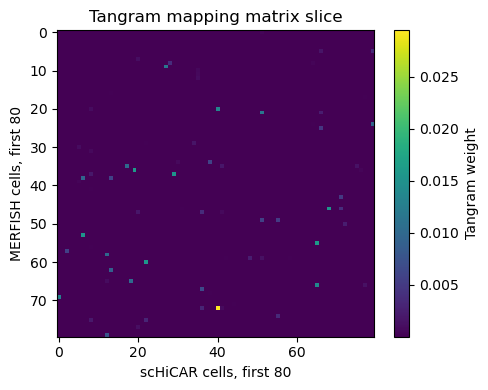

In [7]:
W = mdata.mod["tangram_mapping"].X
print("mapping shape:", W.shape)

# Read only a small slice for visualization.
small = W[:80, :80]
if hasattr(small, "toarray"):
    small = small.toarray()
small = np.asarray(small)

plt.figure(figsize=(5, 4))
plt.imshow(small, aspect="auto", interpolation="nearest")
plt.colorbar(label="Tangram weight")
plt.xlabel("scHiCAR cells, first 80")
plt.ylabel("MERFISH cells, first 80")
plt.title("Tangram mapping matrix slice")
plt.tight_layout()
plt.show()


### Example: project one scHiCAR Hi-C feature to MERFISH space

This reads one feature vector from `schicar_hic_features` and projects it using
the Tangram mapping matrix. The result is one value per MERFISH cell.


In [8]:
hic = mdata.mod["schicar_hic_features"]
feature_names = list(hic.var_names)
feature_name = feature_names[0]
f = np.asarray(hic[:, feature_name].X).reshape(-1)

valid = np.isfinite(f).astype(np.float32)
f0 = np.where(np.isfinite(f), f, 0.0).astype(np.float32)

W = mdata.mod["tangram_mapping"].X
projected_num = W @ f0
projected_den = W @ valid
projected = np.divide(projected_num, projected_den, out=np.full_like(projected_num, np.nan), where=projected_den != 0)

print("feature:", feature_name)
print("projected shape:", projected.shape)
print(pd.Series(projected).describe())


feature: n_contacts
projected shape: (13864,)
count    13864.000000
mean     22551.806641
std       2685.689453
min      13575.076172
25%      20690.797852
50%      22381.464844
75%      24257.307129
max      34912.632812
dtype: float64


## 5. ATAC and paper-derived 3D structure features

The framework keeps ATAC and paper-derived 3D genome features as explicit
modalities rather than hiding them in general metadata.


In [9]:
for name in ["schicar_atac_1mb", "schicar_hic_features", "paper_loop_density_5kb", "scdeeplucia_loop_density_5kb"]:
    adata = mdata.mod[name]
    print("\n", name, adata.shape)
    print("X dtype:", getattr(adata.X, "dtype", type(adata.X)))
    print("obs index name:", adata.obs.index.name)
    print("var index name:", adata.var.index.name)



 schicar_atac_1mb (5163, 2645)
X dtype: float32
obs index name: schicar_cell_id
var index name: genome_bin_1Mb

 schicar_hic_features (5163, 8)
X dtype: float32
obs index name: schicar_cell_id
var index name: hic_feature

 paper_loop_density_5kb (22, 2645)
X dtype: float32
obs index name: cell_type
var index name: genome_bin_1Mb

 scdeeplucia_loop_density_5kb (22, 2645)
X dtype: float32
obs index name: cell_type
var index name: genome_bin_1Mb


## 6. Read the raw scHiCAR scool contacts

The raw contact matrices stay in scool format. The H5CD links to this file,
but does not copy it.


In [10]:
scool_path = Path(summary["outputs"]["scool"])
print("is scool:", cooler.fileops.is_scool_file(str(scool_path)))
cells = cooler.fileops.list_scool_cells(str(scool_path))
print("n scool cells:", len(cells))
print("first cells:", cells[:5])

first = cells[0]
c = cooler.Cooler(f"{scool_path}::{first}")
print("first cooler bins:", c.bins().shape[0])
print("first cooler pixels:", c.pixels().shape[0])


is scool: True


n scool cells: 5163
first cells: ['/cells/ACGAACAAACTCAGACTT', '/cells/ACGAACAAACTCATTTGG', '/cells/ACGAACAAACTCCGTATT', '/cells/ACGAACAAACTCGATAGG', '/cells/ACGAACAAACTCTATCGC']
first cooler bins: 2645
first cooler pixels: 22100


## 7. Summary

The organized framework should be interpreted as:

```text
H5CD   = U-Chrom spatialized view and links
H5MU   = MuData multi-modal matrices and Tangram evidence
scool  = raw scHiCAR contact matrices
```

The H5CD `coords` are intentionally missing. Tangram gives cell-level spatial
mapping, not per-genomic-bin xyz coordinates.

### What U-Chrom contributes now

For this dataset, U-Chrom currently provides a data model and integration
contract:

- one H5CD entry point for a spatialized view;
- explicit links to MuData and scool evidence;
- clear `spot_semantics` for cell-by-genomic-bin feature rows;
- explicit `coordinate_status` showing that per-bin 3D coordinates are not
  available;
- a place to store cell-level spatial metadata and provenance without
  confusing it with chromatin-structure coordinates.

U-Chrom is not performing the Tangram alignment or the original scHiCAR loop
calling in this notebook. Those results are treated as upstream evidence and
organized into a readable framework.

### What U-Chrom could do later

If single-cell Hi-C/scHiCAR contacts are later reconstructed into per-cell
3D genome structures, the same framework can become a full ChromData object:

```text
cells  = scHiCAR cells with Tangram/MERFISH spatial metadata
spots  = scHiCAR cell x genomic bin rows
coords = predicted per-cell per-bin 3D genome coordinates
layers = alternative reconstruction methods or uncertainty-aware coordinates
links  = raw scool contacts, MuData modalities, and Tangram evidence
```

At that point, U-Chrom would move from being mostly an organization layer to
being the primary container for spatially located single-cell 3D genome
structures.


In [11]:
mdata.file.close()
print("Notebook inspection complete.")


Notebook inspection complete.
